- 基础学习器覆盖四个模型家族：
  - 线性/响应面族：多项式回归 PR
  - 核方法族：SVR(RBF)、核岭回归(KRR)、高斯过程GPR(Matérn-ARD)
  - 近邻族：KNN(距离加权)
  - 树族：**Bagging**（自助采样×决策树平均）与**梯度提升**（浅决策树逐轮拟合残差）
- 集成方式：**OOF非负加权融合**。用分组交叉验证得到每个基学习器的袋外(OOF)预测，在工况均值口径下用**非负最小二乘(NNLS)**学习融合权重 —— 权重非负保证可解释（每个成员的贡献占比一目了然），表现差的成员权重自动归零，自动剔除
- 评估采用**嵌套GroupKFold**：外层8折评估，内层5折产生OOF学权重，权重学习永远见不到外层测试工况，杜绝"用测试集调融合权重"的泄漏


| 集成模型 | 内部学习器 | 数量 | 组合方式 |
|---|---|---|---|
| **MyBagging** | 决策树 | 300棵 | 每棵在一份有放回自助采样的数据上独立训练，预测取**平均**（并行降方差） |
| **MyGBoost** | 决策树 | 400棵 | 从全局均值出发，每棵拟合上一轮的**残差**，乘学习率0.05逐轮**累加**（串行降偏差） |

**MyBagging（并行降方差）**：对训练集做B次有放回自助采样，各训练一棵（可较深的）决策树，预测取平均。单棵深树方差大、偏差小，平均后方差按近似 1/B 收缩。可选 `max_features` 在每棵树上随机采样特征子集，进一步去相关。            
**MyGBoost（串行降偏差）**：从全局均值 F₀ 出发，每轮用一棵**浅**决策树拟合当前残差 y−F，再以学习率 η 缩步累加：F ← F + η·h。浅树偏差大但稳，几百轮小步累积逼近复杂响应面；`subsample<1` 时每轮只用随机子样本拟合（随机梯度提升），额外正则。   


#### OOF异质加权集成模型
| 家族 | 成员 | 说明 |
|---|---|---|
| 线性/响应面 | **RSM2** | 二次多项式特征 + 岭回归，契合CCD实验设计 |
| 核方法 | **SVR** | RBF核支持向量回归 |
| 核方法 | **KRR** | RBF核岭回归 |
| 核方法 | **GPR-ARD** | Matérn核高斯过程，每维独立长度尺度 |
| 核方法 | **GPR-dir** | 增广"(方向−1.5)×各因子"特征的GPR，替代原分方向建模 |
| 近邻 | **KNN** | k近邻，距离加权 |
| 树集成 | **MyBagging** | Bagging |
| 树集成 | **MyGBoost** | 梯度提升 |

In [1]:
import os, sys, time, warnings
import numpy as np, pandas as pd
import importlib

warnings.filterwarnings('ignore')
sys.path.insert(0, os.getcwd())   

if mod := sys.modules.get('集成公共函数'):
    imported_names = [
        name for name in dir(mod)
        if not name.startswith("_")
    ]
    g = globals()
    for name in imported_names:
        g.pop(name, None)
    importlib.reload(mod)
from 集成公共函数 import *

import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']  
plt.rcParams['axes.unicode_minus'] = False


OUT_DIR   = MODEL_DIR
ARTIFACT  = ARTIFACT_PATH
COMP_XLSX = EXT_PRED_CMP_PATH

# 数据完整性自检
INTEGRITY = check_data_integrity()

[数据自检] 汇总-均值 与 试样级分表一致 rel_tol=0.0001, abs_tol=0.001


In [2]:
# ---原始数据集---
demo = load_long('拉伸强度')
print('试样级样本数:', len(demo), '| 工况数:', demo['cond'].nunique())
demo.head(6)

# ---外部验证数据---
demo2 = load_external()
print('外部验证数据集样本数:', {k: len(v) for k, v in demo2.items()})

试样级样本数: 186 | 工况数: 62
外部验证数据集样本数: {'FS': 8, 'FM': 8, 'TS': 8, 'TM': 8, 'IS': 8}


In [3]:
# 基学习器
MEMBERS = list(base_learners().keys())
print('基学习器:', MEMBERS)

基学习器: ['Polynomial Regression', 'SVR', 'KNN', 'GPR-ARD', 'GPR-dir', 'Bagging', 'GBoost', 'RF', 'ExtraTrees', 'GBM', 'AdaBoost', 'Lasso']


In [4]:
# 网格调优
#全量训练数据，所选超参数只能给最终部署模型用
TUNED, CV_SCORES, BEST_PARAMS, TUNE_META = {}, {}, {}, {}
for tag in SHEETS.values():
    TUNED[tag], CV_SCORES[tag], BEST_PARAMS[tag], TUNE_META[tag] = tune_all(tag, verbose=True)


  [TS] Polynomial Regression 全量数据调优CV R2= 0.135 | {'ridge__alpha': 1}
  [TS] SVR          全量数据调优CV R2= 0.083 | {'svr__C': 100, 'svr__gamma': 0.3}
  [TS] KNN          全量数据调优CV R2=-0.219 | {'kneighborsregressor__n_neighbors': 9}
  [TS] GPR-ARD      全量数据调优CV R2= 0.294 | {'gaussianprocessregressor__kernel': 1**2 * Matern(length_scale=[1, 1, 1, 1, 1], nu=1.5) + WhiteKernel(noise_level=0.01)}
  [TS] GPR-dir      全量数据调优CV R2= 0.390 | {'gaussianprocessregressor__kernel': 1**2 * Matern(length_scale=1, nu=1.5) + WhiteKernel(noise_level=0.01)}
  [TS] Bagging      全量数据调优CV R2= 0.383 | {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 200}
  [TS] GBoost       全量数据调优CV R2= 0.446 | {'learning_rate': 0.08, 'max_depth': 3, 'n_estimators': 200}
  [TS] RF           全量数据调优CV R2= 0.384 | {'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__n_estimators': 100}
  [TS] ExtraTrees   全量数据调优CV R2= 0.364 | {'extratreesregresso

In [5]:
# 在嵌套交叉内部的各目标集成模型的超参数组合表 / 各学习器的交叉评估指标值
HP_WIDE, HP_LONG = {}, []
for tag in SHEETS.values():
    wide, long_df = build_hyperparam_tables(TUNED[tag], CV_SCORES[tag],
                                            BEST_PARAMS[tag], TUNE_META[tag])
    HP_WIDE[tag] = wide
    HP_LONG.append(long_df)
    print(f'\n===== {TAG_CN[tag]} ({tag}) 基学习器最优超参数组合 =====')
    display(wide)
HP_LONG = pd.concat(HP_LONG, ignore_index=True)


# 成员CV得分矩阵
CV_MAT = pd.DataFrame({tag: CV_SCORES[tag] for tag in SHEETS.values()}).T
CV_MAT.index.name = '目标'
print('\n成员试样级CV R2矩阵:')
display(CV_MAT)


===== 拉伸强度 (TS) 基学习器最优超参数组合 =====


,学习器,最优参数组合,CV_R2,调优耗时_s
0,Polynomial Regression,ridge__alpha=1,0.1347,20.8
1,SVR,svr__C=100; svr__gamma=0.3,0.0830,20.8
2,KNN,kneighborsregressor__n_neighbors=9,-0.2191,20.8
3,GPR-ARD,gaussianprocessregressor__kernel=1**2 * Matern...,0.2937,20.8
4,GPR-dir,gaussianprocessregressor__kernel=1**2 * Matern...,0.3904,20.8
5,Bagging,max_depth=8; max_features=None; min_samples_le...,0.3835,20.8
6,GBoost,learning_rate=0.08; max_depth=3; n_estimators=200,0.4456,20.8
7,RF,randomforestregressor__max_depth=None; randomf...,0.3844,20.8
8,ExtraTrees,extratreesregressor__max_depth=8; extratreesre...,0.3642,20.8
9,GBM,gradientboostingregressor__learning_rate=0.1; ...,0.3563,20.8



===== 弹性模量 (TM) 基学习器最优超参数组合 =====


,学习器,最优参数组合,CV_R2,调优耗时_s
0,Polynomial Regression,ridge__alpha=0.1,0.1303,18.4
1,SVR,svr__C=300; svr__gamma=scale,0.0285,18.4
2,KNN,kneighborsregressor__n_neighbors=9,-0.1899,18.4
3,GPR-ARD,gaussianprocessregressor__kernel=1**2 * Matern...,-0.0624,18.4
4,GPR-dir,gaussianprocessregressor__kernel=1**2 * Matern...,0.1413,18.4
5,Bagging,max_depth=None; max_features=3; min_samples_le...,-0.2222,18.4
6,GBoost,learning_rate=0.08; max_depth=2; n_estimators=400,0.2120,18.4
7,RF,randomforestregressor__max_depth=None; randomf...,-0.4587,18.4
8,ExtraTrees,extratreesregressor__max_depth=None; extratree...,-0.5037,18.4
9,GBM,gradientboostingregressor__learning_rate=0.1; ...,0.0653,18.4



===== 弯曲强度 (FS) 基学习器最优超参数组合 =====


,学习器,最优参数组合,CV_R2,调优耗时_s
0,Polynomial Regression,ridge__alpha=100,0.1811,18.0
1,SVR,svr__C=100; svr__gamma=0.1,0.5853,18.0
2,KNN,kneighborsregressor__n_neighbors=7,0.2484,18.0
3,GPR-ARD,gaussianprocessregressor__kernel=1**2 * Matern...,0.7261,18.0
4,GPR-dir,gaussianprocessregressor__kernel=1**2 * Matern...,0.5305,18.0
5,Bagging,max_depth=8; max_features=None; min_samples_le...,0.6918,18.0
6,GBoost,learning_rate=0.05; max_depth=3; n_estimators=200,0.7699,18.0
7,RF,randomforestregressor__max_depth=8; randomfore...,0.6926,18.0
8,ExtraTrees,extratreesregressor__max_depth=None; extratree...,0.6657,18.0
9,GBM,gradientboostingregressor__learning_rate=0.05;...,0.7817,18.0


... (2 outputs left out)


===== 冲击强度 (IS) 基学习器最优超参数组合 =====


,学习器,最优参数组合,CV_R2,调优耗时_s
0,Polynomial Regression,ridge__alpha=1,0.3133,17.0
1,SVR,svr__C=300; svr__gamma=0.3,0.1686,17.0
2,KNN,kneighborsregressor__n_neighbors=9,0.0533,17.0
3,GPR-ARD,gaussianprocessregressor__kernel=1**2 * Matern...,0.3757,17.0
4,GPR-dir,gaussianprocessregressor__kernel=1**2 * Matern...,0.3303,17.0
5,Bagging,max_depth=8; max_features=3; min_samples_leaf=...,0.3873,17.0
6,GBoost,learning_rate=0.03; max_depth=2; n_estimators=200,0.3321,17.0
7,RF,randomforestregressor__max_depth=None; randomf...,0.3899,17.0
8,ExtraTrees,extratreesregressor__max_depth=None; extratree...,0.3733,17.0
9,GBM,gradientboostingregressor__learning_rate=0.05;...,0.3555,17.0



成员试样级CV R2矩阵:


,Polynomial Regression,SVR,KNN,GPR-ARD,GPR-dir,Bagging,GBoost,RF,ExtraTrees,GBM,AdaBoost,Lasso
目标,,,,,,,,,,,,
TS,0.134744,0.083016,-0.219150,0.293657,0.390381,0.383480,0.445579,0.384352,0.364218,0.356335,0.417848,-0.047224
TM,0.130349,0.028521,-0.189873,-0.062429,0.141259,-0.222224,0.211990,-0.458737,-0.503672,0.065319,-0.138387,-0.410903
FS,0.181089,0.585303,0.248437,0.726104,0.530504,0.691793,0.769856,0.692639,0.665705,0.781689,0.643682,0.219412
FM,0.366790,0.360773,0.180164,0.552573,0.442338,0.569053,0.599362,0.487330,0.459533,0.587112,0.531342,0.355316
IS,0.313278,0.168581,0.053277,0.375705,0.330260,0.387321,0.332081,0.389945,0.373315,0.355535,0.335105,0.219086


#### OOF 非负加权融合（NNLS）+ 嵌套评估
**融合原理**：对训练数据做分组K折，得到每个基学习器的袋外(OOF)预测矩阵 P（168×学习器个数）。把 P 与 y 都聚合到工况均值口径后，解非负最小二乘
$$\min_{w \ge 0} \; \lVert \bar{P} w - \bar{y} \rVert^2$$

得到融合权重 w。非负约束的两个好处：权重可直接解读为"成员贡献占比"；对某目标无益的成员权重被压到0，**自动完成成员筛选**
外层 GroupKFold(8) 负责报告指标；每个外层训练集内部再做 GroupKFold(5) 产生OOF学权重。**外层测试工况从未参与权重学习**

In [ ]:
# 嵌套评估
# 每个外层折内部重新做 GridSearchCV
NEST, t_all = {}, time.time()
for tag in SHEETS.values():
    t0 = time.time()
    NEST[tag] = nested_oof_v2(tag, tuned=TUNED[tag], nested_tune=NESTED_TUNE,
                              n_outer=N_OUTER, n_inner=N_INNER,
                              per_fold=True, verbose=True)
    print(f'  [{tag}] 完成 ({time.time()-t0:.0f}s)')

res_ens = pd.DataFrame([evaluate_oof(t, NEST[t]['oof'], NEST[t]['y'], NEST[t]['cond'])
                        for t in SHEETS.values()])
print(f'\n嵌套评估总耗时 {time.time()-t_all:.0f}s | 超参数: 'f'{"折内重新调优" if NESTED_TUNE else "复用全量调优"}')
res_ens

  [TS] 嵌套交叉外层折 1/8 完成
  [TS] 嵌套交叉外层折 2/8 完成
  [TS] 嵌套交叉外层折 3/8 完成
  [TS] 嵌套交叉外层折 4/8 完成
  [TS] 嵌套交叉外层折 5/8 完成
  [TS] 嵌套交叉外层折 6/8 完成
  [TS] 嵌套交叉外层折 7/8 完成
  [TS] 嵌套交叉外层折 8/8 完成
  [TS] nested_oof_v2 总耗时 162s 
  [TS] 完成 (162s)
  [TM] 嵌套交叉外层折 1/8 完成
  [TM] 嵌套交叉外层折 2/8 完成
  [TM] 嵌套交叉外层折 3/8 完成
  [TM] 嵌套交叉外层折 4/8 完成
  [TM] 嵌套交叉外层折 5/8 完成
  [TM] 嵌套交叉外层折 6/8 完成
  [TM] 嵌套交叉外层折 7/8 完成
  [TM] 嵌套交叉外层折 8/8 完成
  [TM] nested_oof_v2 总耗时 169s 
  [TM] 完成 (169s)
  [FS] 嵌套交叉外层折 1/8 完成
  [FS] 嵌套交叉外层折 2/8 完成
  [FS] 嵌套交叉外层折 3/8 完成
  [FS] 嵌套交叉外层折 4/8 完成
  [FS] 嵌套交叉外层折 5/8 完成
  [FS] 嵌套交叉外层折 6/8 完成
  [FS] 嵌套交叉外层折 7/8 完成
  [FS] 嵌套交叉外层折 8/8 完成
  [FS] nested_oof_v2 总耗时 313s 
  [FS] 完成 (313s)
  [FM] 嵌套交叉外层折 1/8 完成
  [FM] 嵌套交叉外层折 2/8 完成
  [FM] 嵌套交叉外层折 3/8 完成
  [FM] 嵌套交叉外层折 4/8 完成
  [FM] 嵌套交叉外层折 5/8 完成
  [FM] 嵌套交叉外层折 6/8 完成
  [FM] 嵌套交叉外层折 7/8 完成
  [FM] 嵌套交叉外层折 8/8 完成
  [FM] nested_oof_v2 总耗时 464s 
  [FM] 完成 (464s)
  [IS] 嵌套交叉外层折 1/8 完成
  [IS] 嵌套交叉外层折 2/8 完成
  [IS] 嵌套交叉外层折 3/8 完成
  [IS] 嵌套交叉外层折 4/8 完成
  [IS] 嵌套交叉外层折 5

,目标,R2,RMSE,MAPE,n_cond
0,TS,0.455,6.94,4.81,62
1,TM,0.373,1105.07,5.61,62
2,FS,0.811,9.08,4.05,62
3,FM,0.676,484.82,4.17,62
4,IS,0.399,2.48,10.31,62


In [7]:
#全数据拟合最终集成
# 最终模型：用全部186条做一次OOF学权重，再全数据拟合8个成员
ENSEMBLES, W_raw, BEST_SINGLE, MAXW_SINGLE = {}, {}, {}, {}
for tag in SHEETS.values():
    ENSEMBLES[tag], W_raw[tag], BEST_SINGLE[tag], MAXW_SINGLE[tag] = \
        build_final_ensemble(tag, TUNED[tag], CV_SCORES[tag], verbose=False)

_MEMBER_NAMES = list(base_learners().keys())
WEIGHTS_TABLE = pd.DataFrame(
    {tag: np.round(w / w.sum(), 3) for tag, w in W_raw.items()},
    index=_MEMBER_NAMES)
WEIGHTS_TABLE.index.name = '学习器'



#-------权重稳定性：逐折权重是否稳定-------
_ws = {}
for _t in SHEETS.values():
    _dfw = pd.DataFrame(NEST[_t]['fold_w'], columns=_MEMBER_NAMES)
    _ws[_t] = _dfw.agg(['mean', 'std'])
WEIGHT_STABILITY = pd.concat(_ws, axis=1).sort_index(axis=1)

print('融合权重占比:')
display(WEIGHTS_TABLE)
_keep = [m for m in WEIGHTS_TABLE.index if (WEIGHTS_TABLE.loc[m] > 0.01).any()]
print('\n逐折权重稳定性 mean / std:')
display(WEIGHT_STABILITY.loc[:, (slice(None), _keep)].round(3))


融合权重占比:


,TS,TM,FS,FM,IS
学习器,,,,,
Polynomial Regression,0.023,0.148,0.000,0.028,0.000
SVR,0.000,0.000,0.000,0.000,0.103
KNN,0.000,0.000,0.000,0.052,0.000
GPR-ARD,0.000,0.016,0.262,0.118,0.359
GPR-dir,0.233,0.236,0.000,0.000,0.000
Bagging,0.000,0.000,0.000,0.000,0.000
GBoost,0.504,0.600,0.141,0.637,0.000
RF,0.000,0.000,0.000,0.000,0.538
ExtraTrees,0.000,0.000,0.000,0.000,0.000



逐折权重稳定性 mean / std:


,FM,FS,IS,TM,TS,FM,FS,IS,TM,TS,...,FM,FS,IS,TM,TS,FM,FS,IS,TM,TS
,Polynomial Regression,Polynomial Regression,Polynomial Regression,Polynomial Regression,Polynomial Regression,SVR,SVR,SVR,SVR,SVR,...,GBM,GBM,GBM,GBM,GBM,AdaBoost,AdaBoost,AdaBoost,AdaBoost,AdaBoost
mean,0.011,0.0,0.125,0.118,0.025,0.002,0.026,0.020,0.050,0.0,...,0.167,0.247,0.078,0.212,0.05,0.033,0.096,0.191,0.004,0.052
std,0.021,0.0,0.170,0.124,0.071,0.006,0.073,0.057,0.082,0.0,...,0.240,0.376,0.130,0.241,0.14,0.072,0.139,0.245,0.010,0.148


In [8]:
from sklearn.model_selection import GroupShuffleSplit

plt.rcParams.update({
    'font.size':14,'axes.labelsize':18,'axes.titlesize':16,
    'xtick.labelsize':16,'ytick.labelsize':16,'legend.fontsize':12,
    'figure.dpi':400,'savefig.dpi':800,'savefig.bbox':'tight',
    'axes.linewidth':1.2,'xtick.major.width':1.2,'ytick.major.width':1.2,
    'xtick.major.size':6,'ytick.major.size':6,'xtick.minor.size':3,'ytick.minor.size':3,
    'axes.spines.top':True,'axes.spines.right':True,'axes.unicode_minus':False})

SCI = ['#2E86AB','#A23B72','#F18F01','#C73E1D','#649fca',
       '#c68f5f','#63bd63','#D05E5E','#8F51C8']
MEMBERS   = list(base_learners().keys())
MCOLOR    = {m: SCI[i % 8] for i, m in enumerate(MEMBERS)}
ENS_COLOR = SCI[8]

def cond_mean(y, p, cond):
    "把同工况的多个试验整理为一条均值记录"
    df = pd.DataFrame(dict(y=y, p=p, cond=cond)).groupby('cond').mean()
    return df['y'].values, df['p'].values

# 直接复用嵌套结果
DIAG = NEST
print('口径:', DIAG[list(DIAG)[0]]['group_mode'],
      '| 折内调优:', DIAG[list(DIAG)[0]]['nested_tune'],
      '| 外层折数:', DIAG[list(DIAG)[0]]['n_outer'])


口径: combo | 折内调优: True | 外层折数: 8


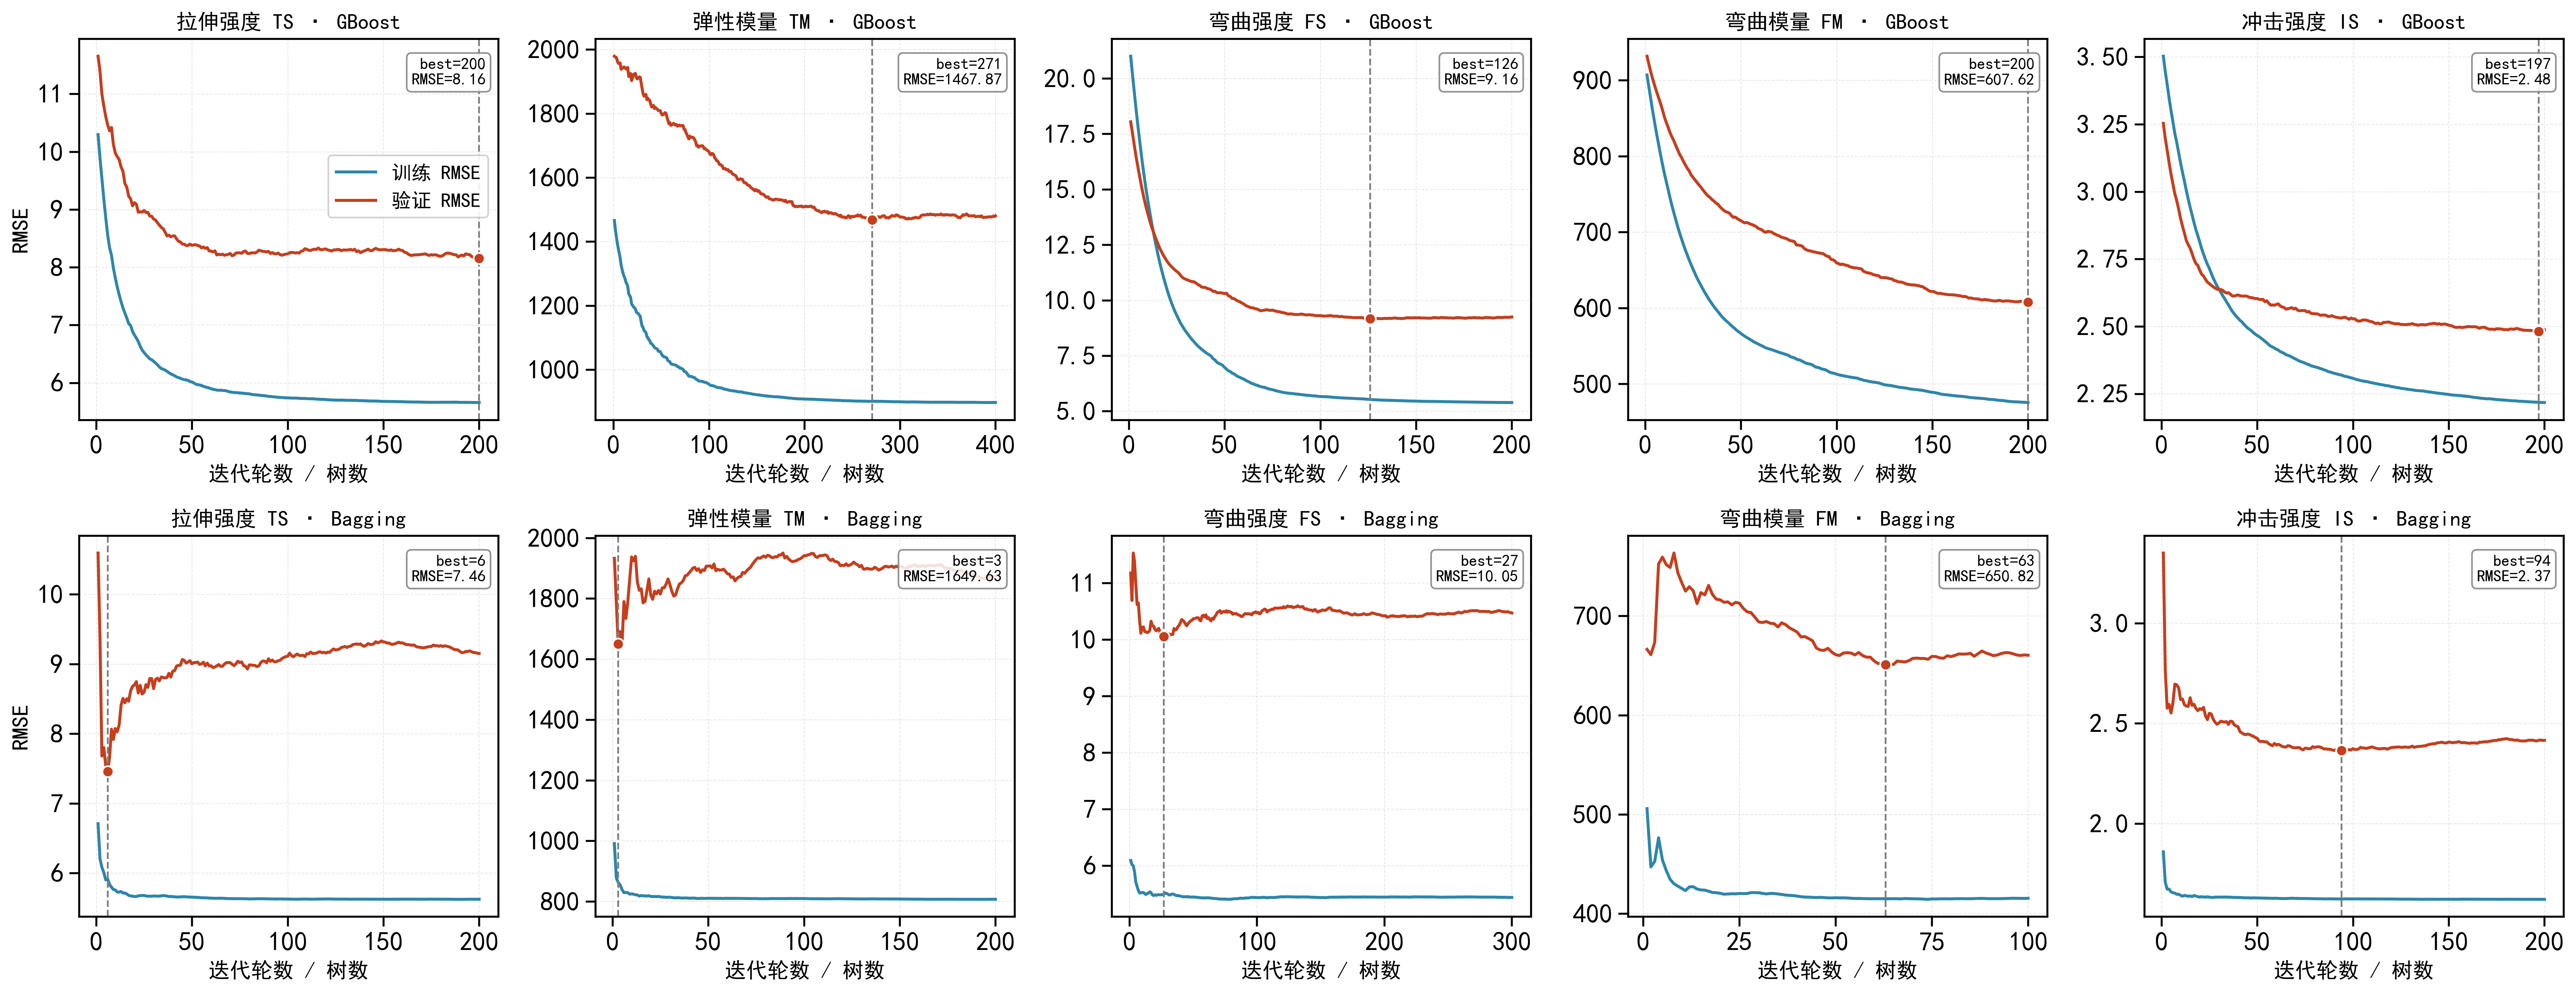

In [9]:
#集成的训练收敛曲线（MyGBoost / MyBagging）
def staged_curves(tag, seed=0, test_size=0.25):
    d = DIAG[tag]['d']
    X, y = d[FEATS].values.astype(float), d['y'].values
    tr, va = next(GroupShuffleSplit(1, test_size=test_size,
                                    random_state=seed).split(
        X, y, groups=group_labels(d)))
    out = {}
    gb = clone(TUNED[tag]['GBoost']).fit(X[tr], y[tr])
    for split, (Xs, ys) in dict(train=(X[tr], y[tr]), valid=(X[va], y[va])).items():
        stage = gb.F0_ + gb.learning_rate * np.cumsum(
            [t.predict(Xs) for t in gb.trees_], axis=0)
        out[f'GB_{split}'] = np.sqrt(((stage - ys) ** 2).mean(axis=1))
    bg = clone(TUNED[tag]['Bagging']).fit(X[tr], y[tr])
    for split, (Xs, ys) in dict(train=(X[tr], y[tr]), valid=(X[va], y[va])).items():
        cum = np.cumsum([t.predict(Xs) for t in bg.trees_], axis=0) \
              / np.arange(1, len(bg.trees_) + 1)[:, None]
        out[f'BG_{split}'] = np.sqrt(((cum - ys) ** 2).mean(axis=1))
    return out

tags = list(SHEETS.values())
fig, axes = plt.subplots(2, len(tags), figsize=(4.4*len(tags), 8.6))
axes = np.atleast_2d(axes)
for j, tag in enumerate(tags):
    cv = staged_curves(tag)
    for i, (pre, name) in enumerate([('GB', 'GBoost'), ('BG', 'Bagging')]):
        ax = axes[i, j]
        trc, vac = cv[f'{pre}_train'], cv[f'{pre}_valid']
        it = np.arange(1, len(trc) + 1)
        ax.plot(it, trc, color=SCI[0], lw=1.8, label='训练 RMSE')
        ax.plot(it, vac, color=SCI[3], lw=1.8, label='验证 RMSE')
        b = int(np.argmin(vac))
        ax.axvline(b + 1, color='gray', ls='--', lw=1.1)
        ax.scatter([b + 1], [vac[b]], s=45, color=SCI[3],
                   edgecolor='white', zorder=5)
        ax.text(0.97, 0.95, f'best={b+1}\nRMSE={vac[b]:.2f}',
                transform=ax.transAxes, ha='right', va='top', fontsize=10,
                bbox=dict(boxstyle='round,pad=0.3', fc='white',
                          ec='gray', alpha=0.85))
        ax.set_title(f'{TAG_CN[tag]} {tag} · {name}', fontsize=13)
        ax.set_xlabel('迭代轮数 / 树数', fontsize=13)
        if j == 0: ax.set_ylabel('RMSE', fontsize=14)
        ax.grid(alpha=0.3, ls='--', lw=0.5)
        if i == 0 and j == 0:
            ax.legend(loc='upper right', bbox_to_anchor=(1, 0.72),
                      frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig9_1_收敛曲线.png'))
plt.show()


折间稳定性 mean ± SD


目标,FM,FS,IS,TM,TS
模型,,,,,
AdaBoost,0.373,0.548,0.214,-0.304,0.317
Bagging,0.422,0.563,0.222,-0.327,0.299
Ensemble,0.441,0.713,0.158,0.082,0.234
ExtraTrees,0.279,0.532,0.199,-0.532,0.305
GBM,0.381,0.692,0.129,-0.306,0.172
GBoost,0.416,0.696,0.054,0.028,0.160
GPR-ARD,0.294,0.560,0.093,0.109,0.218
GPR-dir,0.278,0.358,0.186,0.301,0.377
KNN,-1.059,-0.513,-0.184,-0.509,-0.484


目标,FM,FS,IS,TM,TS
模型,,,,,
AdaBoost,0.432,0.376,0.570,0.402,0.350
Bagging,0.363,0.326,0.417,0.942,0.419
Ensemble,0.305,0.232,0.554,0.594,0.608
ExtraTrees,0.351,0.352,0.666,0.794,0.333
GBM,0.370,0.254,0.653,1.279,0.660
GBoost,0.314,0.276,0.733,0.642,0.807
GPR-ARD,0.581,0.325,0.589,0.571,0.537
GPR-dir,0.365,0.330,0.450,0.481,0.348
KNN,2.778,1.132,0.728,0.916,0.453


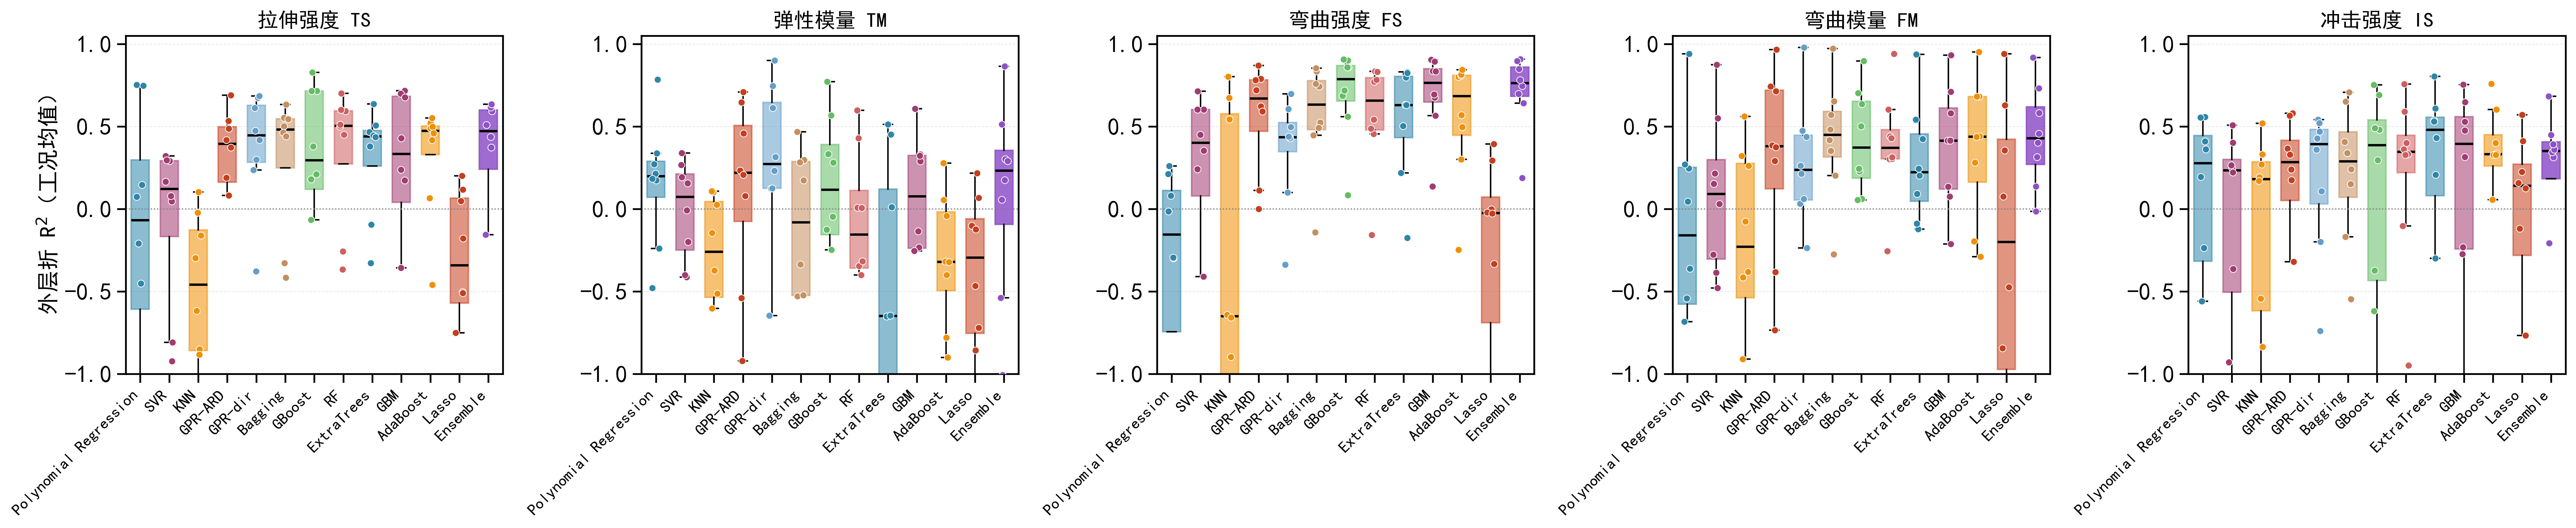

In [10]:
#折间稳定性
tags = list(SHEETS.values())
order = MEMBERS + ['Ensemble']
STAB = []
for tag in tags:
    for m in order:
        v = DIAG[tag]['folds'].loc[DIAG[tag]['folds'].model == m, 'R2'].values
        v = v[np.isfinite(v)]
        STAB.append(dict(目标=tag, 模型=m, 折数=len(v),
                         折间R2均值=round(float(np.mean(v)), 3),
                         折间R2标准差=round(float(np.std(v, ddof=1)), 3),
                         折间R2最小=round(float(np.min(v)), 3),
                         折间R2最大=round(float(np.max(v)), 3)))
STABILITY_TABLE = pd.DataFrame(STAB)
print('折间稳定性 mean ± SD')
display(STABILITY_TABLE.pivot(index='模型', columns='目标',
                              values='折间R2均值').round(3))
display(STABILITY_TABLE.pivot(index='模型', columns='目标',
                              values='折间R2标准差').round(3))

fig, axes = plt.subplots(1, len(tags), figsize=(4.9*len(tags), 5.2), sharey=False)
axes = np.atleast_1d(axes)
rng_j = np.random.default_rng(0)
for j, tag in enumerate(tags):
    ax, fd = axes[j], DIAG[tag]['folds']
    data = [fd.loc[fd.model == m, 'R2'].values for m in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.62, showfliers=False,
                    medianprops=dict(color='black', lw=1.6))
    for patch, m in zip(bp['boxes'], order):
        c = ENS_COLOR if m == 'Ensemble' else MCOLOR[m]
        patch.set_facecolor(c); patch.set_alpha(0.55 if m != 'Ensemble' else 0.85)
        patch.set_edgecolor(c)
    for i, vals in enumerate(data):
        c = ENS_COLOR if order[i] == 'Ensemble' else MCOLOR[order[i]]
        ax.scatter(np.full(len(vals), i+1) + rng_j.uniform(-0.13, 0.13, len(vals)),
                   vals, s=22, color=c, edgecolor='white', lw=0.5, zorder=4)
    lo = np.percentile(np.concatenate(data), 2)
    ax.set_ylim(max(-1.0, lo - 0.1), 1.05)
    ax.axhline(0, color='gray', lw=0.8, ls=':')
    ax.set_xticks(range(1, len(order)+1))
    ax.set_xticklabels(order, rotation=45, ha='right', fontsize=11)
    ax.set_title(f'{TAG_CN[tag]} {tag}', fontsize=14)
    if j == 0: ax.set_ylabel('外层折 R$^2$（工况均值）', fontsize=15)
    ax.grid(axis='y', alpha=0.3, ls='--', lw=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig9_3_折间稳定性.png'))
plt.show()

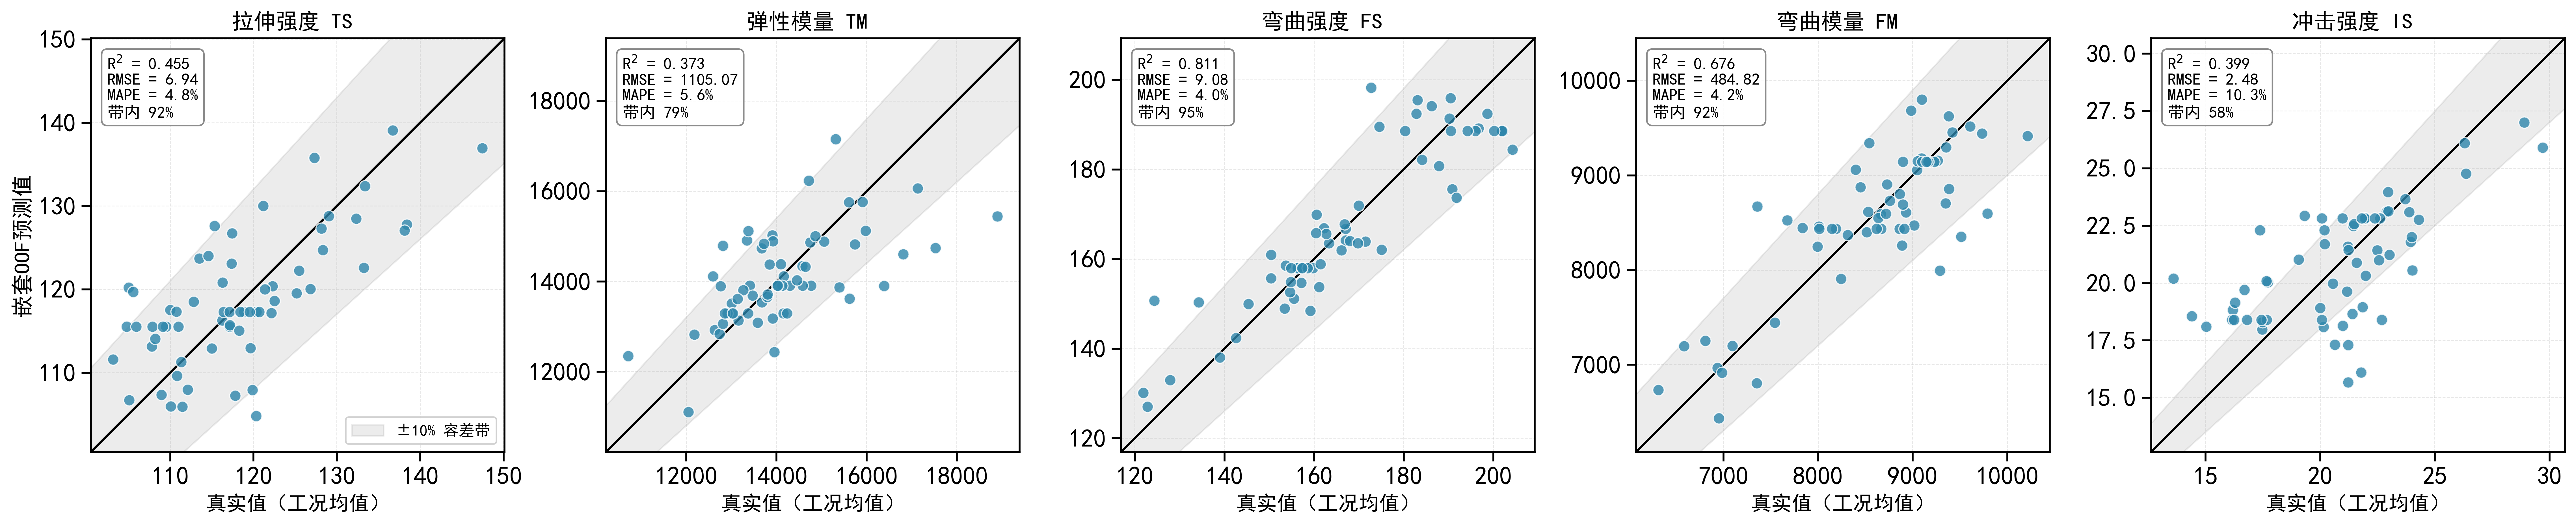

In [11]:
#预测-实测 Parity图
#黑色实线为 y = x，阴影为 ±10% 工程容差带
tags = list(SHEETS.values())
fig, axes = plt.subplots(1, len(tags), figsize=(4.6*len(tags), 4.8))
axes = np.atleast_1d(axes)
for j, tag in enumerate(tags):
    ax, d = axes[j], DIAG[tag]['d']
    yt, pt = cond_mean(d['y'].values, DIAG[tag]['oof'], d['cond'].values)
    lo = min(yt.min(), pt.min()); hi = max(yt.max(), pt.max())
    pad = 0.06 * (hi - lo); lo, hi = lo - pad, hi + pad
    xs = np.linspace(lo, hi, 50)
    ax.fill_between(xs, 0.9*xs, 1.1*xs, color='gray', alpha=0.15,
                    label='±10% 容差带')
    ax.plot(xs, xs, color='black', lw=1.4)
    ax.scatter(yt, pt, s=52, color=SCI[0], alpha=0.8,
               edgecolor='white', lw=0.7, zorder=4)
    r2  = r2_score(yt, pt)
    rmse = mean_squared_error(yt, pt) ** 0.5
    mape = np.mean(np.abs((yt - pt) / yt)) * 100
    inb  = np.mean(np.abs(pt - yt) <= 0.1 * np.abs(yt)) * 100
    ax.text(0.04, 0.96,
            f'R$^2$ = {r2:.3f}\nRMSE = {rmse:.2f}\nMAPE = {mape:.1f}%\n带内 {inb:.0f}%',
            transform=ax.transAxes, va='top', fontsize=10.5,
            bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='gray', alpha=0.9))
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_title(f'{TAG_CN[tag]} {tag} ', fontsize=14)
    ax.set_xlabel('真实值（工况均值）', fontsize=13)
    if j == 0:
        ax.set_ylabel('嵌套OOF预测值', fontsize=14)
        ax.legend(loc='lower right', frameon=True, framealpha=0.9, fontsize=10)
    ax.grid(alpha=0.3, ls='--', lw=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig9_4_parity.png'))
plt.show()

In [12]:
#Excel
os.makedirs(OUT_DIR, exist_ok=True)
OUT_XLSX = os.path.join(OUT_DIR, TRAIN_RESULT_XLSX)

with pd.ExcelWriter(OUT_XLSX) as writer:
    # 嵌套交叉评估结果
    res_ens.to_excel(writer, sheet_name='嵌套评估指标', index=False)
    # 超参数组合
    HP_LONG.to_excel(writer, sheet_name='超参数组合表格', index=False)
    for tag in SHEETS.values():
        HP_WIDE[tag].to_excel(writer, sheet_name=f'超参数组合_{tag}', index=False)
    #稳定性
    STABILITY_TABLE.to_excel(writer, sheet_name='折间稳定性', index=False)
    WEIGHTS_TABLE.to_excel(writer, sheet_name='融合权重占比')
    WEIGHT_STABILITY.round(4).to_excel(writer, sheet_name='权重稳定性')
print('已保存:', OUT_XLSX)

已保存: d:\Code_File\Python_Data_AI\Project_CFPA_Teacher\Data\集成建模\集成模型训练结果.xlsx


In [13]:
# 结果模型存档
ART = dict(ENSEMBLES=ENSEMBLES, TUNED=TUNED, W_raw=W_raw,
           WEIGHTS_TABLE=WEIGHTS_TABLE, CV_SCORES=CV_SCORES,
           BEST_PARAMS=BEST_PARAMS, TUNE_META=TUNE_META,
           NESTED=NEST, 
           BEST_SINGLE=BEST_SINGLE, MAXW_SINGLE=MAXW_SINGLE)
save_artifacts(ART, ARTIFACT)

模型存档已保存: d:\Code_File\Python_Data_AI\Project_CFPA_Teacher\Data\集成建模\集成模型存档.joblib (version=3, group_mode=combo)
